# Chapter 12 — Cross-Validation and Model Evaluation Techniques

**Sumber:** *scikit-learn Cookbook*, 3rd Ed. (John Sukup, Packt, 2025)

Model yang tampak sangat baik pada data latih belum tentu baik pada data baru. Pertanyaan utama setiap proyek *machine learning* adalah: **seberapa baik model ini akan bekerja pada data yang belum pernah dilihatnya?** Satu kali pembagian *train–test* memberi jawaban yang sangat bergantung pada keberuntungan pembagian tersebut. **Validasi silang** (*cross-validation*, CV) mengatasi hal ini dengan melatih dan menguji model berkali-kali pada potongan data yang berbeda, lalu merata-ratakan hasilnya.

Chapter ini membahas strategi CV dasar (K-Fold, Stratified K-Fold), strategi lanjutan (Leave-One-Out dan *nested* CV), API tingkat tinggi scikit-learn (`cross_val_score`, `cross_validate`, `GridSearchCV`), teknik pemilihan model (*grid search* vs *randomized search*), serta diagnosis generalisasi lewat *learning curve* dan *validation curve*.

**Daftar Isi**

1. 12.1 Pengantar Cross-Validation (K-Fold dan Stratified K-Fold)
2. 12.2 Metode Cross-Validation Lanjutan (LOOCV dan Nested CV)
3. 12.3 Implementasi Cross-Validation di scikit-learn
4. 12.4 Teknik Pemilihan Model (GridSearchCV vs RandomizedSearchCV)
5. 12.5 Mengevaluasi Generalisasi Model (Learning Curve dan Validation Curve)
6. Latihan (Exercise 1–3)
7. Ringkasan Chapter 12

> **Catatan:** Notebook ini mereproduksi kode dari Chapter 12 (urutan resep sama dengan notebook resmi Packt), dengan sedikit penyesuaian agar berjalan di scikit-learn 1.9 dan beberapa sel **tambahan** (ditandai "Tambahan") untuk memperjelas konsep. Setiap resep dilengkapi penjelasan teori (bagian **Teori:**) dan tafsiran hasil eksekusi (bagian **Interpretasi:**). Semua dataset berasal dari scikit-learn (`make_classification` dan `load_diabetes`).

## Import Library

In [1]:
%matplotlib inline
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy.stats import loguniform

from sklearn.datasets import make_classification, load_diabetes
from sklearn.model_selection import (KFold, StratifiedKFold, LeaveOneOut,
                                     cross_val_score, cross_validate,
                                     GridSearchCV, RandomizedSearchCV,
                                     train_test_split, learning_curve, validation_curve)
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from IPython.display import display

# Pengaturan tampilan gambar agar ukurannya moderat
plt.rcParams['figure.dpi'] = 90
sns.set_style('whitegrid')

print('numpy        :', np.__version__)
print('pandas       :', pd.__version__)
print('scikit-learn :', sklearn.__version__)

numpy        : 2.5.4
pandas       : 3.1.0
scikit-learn : 1.9.1


## 12.1 Pengantar Cross-Validation (K-Fold dan Stratified K-Fold)

**Teori:**

**Galat generalisasi.** Tujuan kita adalah memperkirakan risiko (galat harapan) model $\hat f$ pada distribusi data sebenarnya,

$$
R(\hat f) = \mathbb{E}_{(x,y)\sim P}\big[L(y, \hat f(x))\big],
$$

dengan $L$ fungsi *loss* (misalnya 0–1 loss untuk akurasi, kuadrat galat untuk MSE). Galat pada data latih adalah penduga yang **bias ke bawah** (terlalu optimistis), karena model sudah "melihat" data tersebut. *Hold-out* (satu kali *train–test split*) memberi penduga tak bias, tetapi variansnya besar dan hanya memakai sebagian data untuk melatih.

**K-Fold cross-validation.** Data dibagi menjadi $K$ bagian (*fold*) $D_1,\dots,D_K$ yang hampir sama besar. Untuk setiap $k$, model dilatih pada $D\setminus D_k$ lalu diuji pada $D_k$:

$$
\widehat{\text{CV}}_K = \frac{1}{K}\sum_{k=1}^{K} \frac{1}{|D_k|}\sum_{i\in D_k} L\big(y_i, \hat f^{(-k)}(x_i)\big).
$$

Setiap observasi dipakai tepat satu kali sebagai data uji dan $K-1$ kali sebagai data latih. Nilai $K$ yang lazim adalah 5 atau 10: setiap model dilatih pada $80$–$90\%$ data, sehingga bias penduga kecil, sementara biaya komputasinya masih wajar ($K$ kali *fit*). Selain rata-rata, **simpangan baku antar fold** memberi gambaran ketidakpastian estimasi.

**Mengacak data (`shuffle=True`).** Secara default `KFold` memotong data berurutan. Jika data tersusun menurut kelas atau waktu pengambilan, fold bisa sangat tidak representatif; `shuffle=True` + `random_state` mengacak indeks terlebih dahulu dengan hasil yang reprodusibel. (Untuk data deret waktu justru **jangan** mengacak — gunakan `TimeSeriesSplit`.)

**Stratified K-Fold.** Pada klasifikasi, pembagian acak bisa menghasilkan fold dengan proporsi kelas yang berbeda dari data penuh — terutama bila kelas tidak seimbang atau data sedikit. `StratifiedKFold` membagi **setiap kelas secara terpisah** ke $K$ fold, sehingga proporsi kelas $\pi_c$ di setiap fold ≈ proporsi di seluruh data. Akibatnya:
- estimasi skor per fold lebih stabil (varians antar fold lebih kecil),
- tidak ada fold yang kehilangan kelas minoritas (yang dapat membuat precision/recall tidak terdefinisi).

Fungsi tingkat tinggi scikit-learn (`cross_val_score`, `GridSearchCV`, dsb.) otomatis memakai `StratifiedKFold` bila `cv` berupa bilangan bulat dan estimatornya adalah *classifier*.

**Pitfall utama:** semua pra-pemrosesan yang "belajar" dari data (scaling, imputasi, seleksi fitur) harus di-*fit* **di dalam** setiap fold (gunakan `Pipeline`), bukan pada seluruh data sebelum CV — jika tidak terjadi *data leakage* dan skor CV menjadi terlalu optimistis.

In [2]:
# Dataset klasifikasi biner sintetis: 500 sampel, 10 fitur (8 informatif, 2 redundan)
X, y = make_classification(n_samples=500, n_features=10, n_informative=8,
                           n_redundant=2, n_classes=2, random_state=2024)

print('Ukuran X:', X.shape)
print('Distribusi kelas:', np.bincount(y), '-> proporsi kelas 1 =', round(y.mean(), 3))

Ukuran X: (500, 10)
Distribusi kelas: [250 250] -> proporsi kelas 1 = 0.5


In [3]:
# K-Fold biasa (5 fold, data diacak terlebih dahulu)
kf = KFold(n_splits=5, shuffle=True, random_state=2024)

accuracies = []
for train_index, test_index in kf.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    model = LogisticRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracies.append(accuracy_score(y_test, y_pred))
print(f"Average accuracy (KFold): {np.mean(accuracies):.3f}")

# Stratified K-Fold: proporsi kelas tiap fold dijaga sama dengan data penuh
strat_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)
strat_accuracies = []
for train_index, test_index in strat_kf.split(X, y):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    model = LogisticRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    strat_accuracies.append(accuracy_score(y_test, y_pred))
print(f"Average accuracy (StratifiedKFold): {np.mean(strat_accuracies):.3f}")

Average accuracy (KFold): 0.756
Average accuracy (StratifiedKFold): 0.766


**Interpretasi:**

- Dataset berisi 500 sampel dengan kelas **seimbang sempurna** (250 : 250).
- Rata-rata akurasi regresi logistik adalah **0.756** dengan `KFold` dan **0.766** dengan `StratifiedKFold`. Kedua angka adalah perkiraan akurasi model pada data baru; perbedaan 0.01 sangat kecil dan tidak berarti satu metode "membuat model lebih baik" — keduanya hanya membagi data dengan cara berbeda. Sel berikut memperlihatkan perbedaan yang lebih penting, yaitu **kestabilan** antar fold.

proporsi_kelas1_test                 accuracy                
cv                  KFold StratifiedKFold    KFold StratifiedKFold
fold                                                              
1                    0.52             0.5     0.72            0.79
2                    0.47             0.5     0.72            0.76
3                    0.54             0.5     0.88            0.76
4                    0.51             0.5     0.71            0.76
5                    0.46             0.5     0.75            0.76

proporsi_kelas1_test         accuracy        
                                mean     std     mean     std
cv                                                           
KFold                            0.5  0.0339    0.756  0.0709
StratifiedKFold                  0.5  0.0000    0.766  0.0134

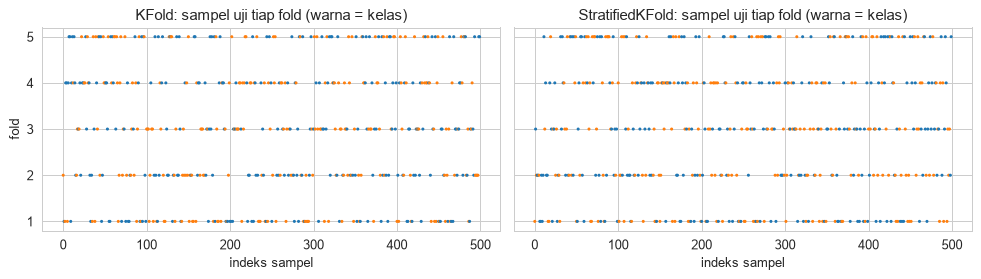

In [4]:
# Tambahan: bandingkan akurasi per fold dan proporsi kelas 1 di setiap fold uji
rows = []
for name, cv in [('KFold', kf), ('StratifiedKFold', strat_kf)]:
    for i, (tr, te) in enumerate(cv.split(X, y), start=1):
        rows.append({'cv': name, 'fold': i, 'n_test': len(te),
                     'proporsi_kelas1_test': y[te].mean()})
fold_df = pd.DataFrame(rows)
fold_df['accuracy'] = accuracies + strat_accuracies
display(fold_df.pivot(index='fold', columns='cv',
                      values=['proporsi_kelas1_test', 'accuracy']).round(3))

summary = fold_df.groupby('cv')[['proporsi_kelas1_test', 'accuracy']].agg(['mean', 'std']).round(4)
display(summary)

# Visualisasi: indeks sampel yang masuk ke fold uji pada masing-masing strategi
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, (name, cv) in zip(axes, [('KFold', kf), ('StratifiedKFold', strat_kf)]):
    for i, (tr, te) in enumerate(cv.split(X, y)):
        ax.scatter(te, np.full(len(te), i + 1), s=2,
                   c=np.where(y[te] == 1, 'tab:orange', 'tab:blue'))
    ax.set_title(f'{name}: sampel uji tiap fold (warna = kelas)')
    ax.set_xlabel('indeks sampel')
axes[0].set_ylabel('fold')
plt.tight_layout()
plt.show()

**Interpretasi:**

- Dengan `KFold`, proporsi kelas 1 di fold uji bervariasi dari **0.46** hingga **0.54** (std 0.034), sedangkan `StratifiedKFold` menjaga proporsi tepat **0.50** di setiap fold (std 0).
- Akurasi per fold `KFold` berkisar **0.71–0.88** (std **0.071**), sementara `StratifiedKFold` hanya **0.76–0.79** (std **0.013**). Jadi walaupun rata-ratanya mirip, estimasi dari Stratified K-Fold jauh lebih stabil — satu fold "beruntung" (0.88 pada KFold fold 3) dapat menarik rata-rata. Inilah alasan stratifikasi menjadi default untuk klasifikasi.
- Plot menunjukkan setiap sampel muncul tepat satu kali di fold uji (indeks tersebar acak karena `shuffle=True`), dan kedua kelas (biru/oranye) tersebar di semua fold.

## 12.2 Metode Cross-Validation Lanjutan (LOOCV dan Nested CV)

**Teori:**

**Leave-One-Out CV (LOOCV)** adalah kasus khusus K-Fold dengan $K=n$: setiap model dilatih pada $n-1$ observasi dan diuji pada 1 observasi yang ditinggalkan,

$$
\widehat{\text{CV}}_{\text{LOO}} = \frac{1}{n}\sum_{i=1}^{n} L\big(y_i, \hat f^{(-i)}(x_i)\big).
$$

- **Bias** sangat kecil karena setiap model memakai hampir seluruh data — cocok untuk dataset kecil.
- **Varians** penduga bisa tinggi: $n$ model yang dilatih hampir identik sehingga galatnya sangat berkorelasi, dan setiap "fold" hanya berisi satu titik (skor per fold tidak bermakna sendiri, misalnya $R^2$ tidak terdefinisi untuk 1 titik — karena itu dipakai MSE).
- **Biaya** komputasi $n$ kali *fit*. Untuk model linear (OLS/Ridge) ada jalan pintas analitis: $\text{LOO}_i = \big(\frac{y_i-\hat y_i}{1-h_{ii}}\big)^2$ dengan $h_{ii}$ elemen diagonal *hat matrix* — inilah yang dipakai `RidgeCV` secara default.

**Mengapa perlu nested CV?** Bila kita memilih hyperparameter $\lambda$ dengan CV lalu melaporkan skor CV terbaik $\max_\lambda \widehat{\text{CV}}(\lambda)$, skor tersebut **bias optimistis**: kita memilih nilai maksimum dari beberapa penduga yang ber-*noise* (*selection bias* / "overfitting ke validation set"). **Nested CV** memisahkan dua tugas:

- **Loop dalam** (*inner*): `GridSearchCV` memilih hyperparameter memakai data latih fold luar saja.
- **Loop luar** (*outer*): model dengan hyperparameter terpilih diuji pada fold luar yang tidak pernah disentuh proses tuning.

Rata-rata skor loop luar adalah estimasi jujur performa **seluruh prosedur** "tuning + fitting". Total *fit* = $K_{\text{out}}\times(K_{\text{in}}\times|\text{grid}| + 1)$; di sini $5\times(5\times5+1)=130$.

**Ridge regression** (lihat Chapter 5) meminimalkan $\lVert \mathbf y - X\boldsymbol\beta\rVert_2^2 + \alpha\lVert\boldsymbol\beta\rVert_2^2$; $\alpha$ adalah hyperparameter yang dituning. Skor default `Ridge.score` adalah koefisien determinasi $R^2 = 1 - \frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$, sehingga skor nested CV di bawah berupa $R^2$, bukan MSE.

**Dataset diabetes** (bawaan scikit-learn): 442 pasien, 10 fitur dasar (usia, jenis kelamin, BMI, tekanan darah, 6 pengukuran serum darah) yang sudah dipusatkan dan diskalakan; target adalah ukuran kuantitatif progresi penyakit satu tahun setelah *baseline*.

In [5]:
# Dataset diabetes (bawaan scikit-learn): 442 pasien, 10 fitur yang sudah distandardisasi
data = load_diabetes()
X = data.data
y = data.target
print('Ukuran X:', X.shape, '| rentang target:', y.min(), '-', y.max(), '| variansi target:', round(y.var(), 1))

Ukuran X: (442, 10) | rentang target: 25.0 - 346.0 | variansi target: 5929.9


In [6]:
# Leave-One-Out CV dengan skor MSE (442 model dilatih)
loo = LeaveOneOut()
model = Ridge(alpha=1.0)
scores = cross_val_score(model, X, y, cv=loo, scoring="neg_mean_squared_error")
print(f"LOOCV mean MSE: {-np.mean(scores):.3f}")

# Grid hyperparameter untuk tuning alpha
param_grid = {"alpha": [0.01, 0.1, 1, 10, 100]}

# Nested CV: GridSearchCV (loop dalam, 5 fold) dibungkus cross_val_score (loop luar, 5 fold)
# Skor default Ridge adalah R^2
nested_scores = cross_val_score(
    GridSearchCV(Ridge(), param_grid, cv=5), X, y, cv=5
)
print(f"Nested CV mean score: {np.mean(nested_scores):.3f}")

LOOCV mean MSE: 3327.655


Nested CV mean score: 0.480


**Interpretasi:**

- **LOOCV MSE = 3327.7**, artinya RMSE ≈ $\sqrt{3327.7}\approx 57.7$ unit progresi penyakit. Sebagai pembanding, variansi target sendiri adalah 5929.9, sehingga Ridge($\alpha=1$) menjelaskan sekitar $1-3327.7/5929.9 \approx 44\%$ variasi.
- **Nested CV mean score = 0.480** — ini adalah $R^2$ (skor default Ridge), bukan MSE, jadi kedua angka tidak dapat dibandingkan langsung. $R^2\approx 0.48$ sesuai dengan yang umum dilaporkan untuk dataset diabetes dengan model linear: model menjelaskan sekitar separuh variasi target.
- Nested CV sedikit lebih baik daripada estimasi LOOCV untuk $\alpha=1$ (≈0.44) karena tuning memilih $\alpha$ yang lebih kecil (lihat sel berikut).

In [7]:
# Tambahan 1: bandingkan LOOCV dengan 5-fold & 10-fold untuk model yang sama
for k in [5, 10]:
    s = cross_val_score(Ridge(alpha=1.0), X, y, cv=KFold(k, shuffle=True, random_state=2024),
                        scoring='neg_mean_squared_error')
    print(f'{k:>2}-fold CV mean MSE : {-s.mean():.3f}  (std antar fold {s.std():.1f})')
print(f'LOOCV mean MSE      : {-scores.mean():.3f}  (std antar titik {scores.std():.1f})')

# Tambahan 2: skor nested vs skor non-nested (best_score_ GridSearchCV pada seluruh data)
outer = KFold(5, shuffle=True, random_state=2024)
inner = KFold(5, shuffle=True, random_state=1)
gs = GridSearchCV(Ridge(), param_grid, cv=inner)
nested_detail = cross_validate(gs, X, y, cv=outer, return_estimator=True)
best_alphas = [est.best_params_['alpha'] for est in nested_detail['estimator']]
gs.fit(X, y)
print('\nalpha terbaik di tiap fold luar :', best_alphas)
print(f"Nested CV R^2 (outer diacak)     : {nested_detail['test_score'].mean():.4f}")
print(f"Non-nested best_score_ (R^2)    : {gs.best_score_:.4f}  -> alpha = {gs.best_params_['alpha']}")

 5-fold CV mean MSE : 3410.849  (std antar fold 301.6)
10-fold CV mean MSE : 3351.379  (std antar fold 639.2)
LOOCV mean MSE      : 3327.655  (std antar titik 3845.6)



alpha terbaik di tiap fold luar : [0.01, 0.1, 0.1, 0.1, 0.01]
Nested CV R^2 (outer diacak)     : 0.4914
Non-nested best_score_ (R^2)    : 0.4809  -> alpha = 0.01


**Interpretasi:**

- MSE dari 5-fold (**3410.8**), 10-fold (**3351.4**) dan LOOCV (**3327.7**) turun sedikit seiring $K$ naik: semakin besar $K$, semakin banyak data latih per model sehingga bias pesimistis penduga berkurang. Selisihnya kecil (≈2.5%), jadi untuk dataset sebesar ini 5- atau 10-fold sudah memadai dengan biaya jauh lebih rendah (5–10 *fit* vs 442).
- Simpangan baku per "fold" LOOCV sangat besar (**3845.6**) karena setiap fold hanya satu titik — kuadrat galat individual sangat bervariasi. Itu sebabnya skor LOOCV hanya bermakna sebagai rata-rata.
- Alpha terbaik yang dipilih di setiap fold luar adalah **0.01 atau 0.1** — tidak sama antar fold, menunjukkan bahwa nested CV mengevaluasi *prosedur* tuning, bukan satu model tertentu. Nilai kecil ini wajar karena fitur diabetes sudah berskala kecil (norma tiap kolom = 1), sehingga $\alpha=1$ sudah merupakan penalti yang relatif kuat.
- Skor nested (**0.491**) dan non-nested `best_score_` (**0.481**) di sini praktis sama; selisihnya berasal dari pembagian fold yang berbeda, bukan bias seleksi. Bias optimistis non-nested baru terasa besar ketika grid luas, model fleksibel, dan data sedikit — pada Ridge dengan 5 kandidat $\alpha$ bias ini dapat diabaikan. Meski begitu, nested CV tetap praktik yang benar ketika kita ingin melaporkan performa yang jujur.

## 12.3 Implementasi Cross-Validation di scikit-learn

**Teori:**

scikit-learn menyediakan tiga tingkat API untuk CV:

| Fungsi | Keluaran | Kapan dipakai |
|---|---|---|
| `cross_val_score(est, X, y, cv, scoring)` | array skor per fold (satu metrik) | evaluasi cepat satu model |
| `cross_validate(est, X, y, cv, scoring=[...])` | dict: `test_<metrik>`, `fit_time`, `score_time`, opsional `train_<metrik>` dan `estimator` | beberapa metrik sekaligus, analisis waktu, inspeksi model per fold |
| `GridSearchCV(est, param_grid, cv, scoring)` | estimator yang sudah di-*refit* dengan parameter terbaik; `best_params_`, `best_score_`, `cv_results_` | tuning hyperparameter |

Parameter `cv` dapat berupa bilangan bulat (untuk *classifier* → `StratifiedKFold` tanpa shuffle), objek splitter, atau iterable indeks. Parameter `scoring` menerima string (`'accuracy'`, `'f1'`, `'roc_auc'`, `'neg_mean_squared_error'`, ...) — metrik galat diberi tanda negatif agar konvensinya selalu "semakin besar semakin baik".

**Metrik klasifikasi** (kelas positif = 1), dengan TP, FP, FN, TN dari *confusion matrix*:

$$
\text{Accuracy}=\frac{TP+TN}{n},\quad
\text{Precision}=\frac{TP}{TP+FP},\quad
\text{Recall}=\frac{TP}{TP+FN},\quad
F_1=\frac{2\cdot\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}.
$$

Pada data **tidak seimbang**, akurasi bisa menyesatkan: dengan 70% kelas negatif, model yang selalu menebak "negatif" sudah mendapat akurasi 0.70 tetapi recall 0. Karena itu precision, recall dan F1 perlu dilaporkan bersama.

**Regresi logistik** memodelkan $P(y=1\mid x)=\sigma(\mathbf w^\top x + b)$ dengan $\sigma(z)=1/(1+e^{-z})$ dan meminimalkan *log-loss* ditambah penalti L2. Di scikit-learn kekuatan regularisasi diatur oleh $C$ — **kebalikan** dari $\alpha$: $C$ kecil = penalti kuat (model sederhana), $C$ besar = penalti lemah.

**Catatan penting `GridSearchCV`:** `best_score_` adalah rata-rata skor CV kandidat terbaik — angka ini sedikit optimistis (lihat 12.2). Jika kita melakukan tuning pada seluruh data seperti di resep ini, tidak ada lagi data "bersih" untuk evaluasi akhir; idealnya sisihkan *test set* (resep 12.4) atau gunakan nested CV.

In [8]:
# Dataset klasifikasi tidak seimbang (70% : 30%)
X, y = make_classification(n_samples=500, n_features=10, weights=[0.7, 0.3], random_state=2024)
print('Distribusi kelas:', np.bincount(y))

Distribusi kelas: [350 150]


In [9]:
# 1) cross_val_score(): satu metrik
model = LogisticRegression()
scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')
print(f"Mean accuracy: {np.mean(scores):.3f}")

# 2) cross_validate(): beberapa metrik sekaligus
results = cross_validate(model, X, y, cv=5,
                         scoring=['accuracy', 'precision', 'recall', 'f1'])
print(f"Mean precision: {np.mean(results['test_precision']):.3f}")
print(f"Mean recall: {np.mean(results['test_recall']):.3f}")
print(f"Mean F1: {np.mean(results['test_f1']):.3f}")

# 3) GridSearchCV(): tuning hyperparameter C dengan validasi silang
param_grid = {"C": [0.01, 0.1, 1, 10]}
grid = GridSearchCV(LogisticRegression(), param_grid, cv=5, scoring='accuracy')
grid.fit(X, y)
print(f"Best hyperparameter (C): {grid.best_params_['C']}")
print(f"Best accuracy: {grid.best_score_:.3f}")

Mean accuracy: 0.910
Mean precision: 0.875
Mean recall: 0.820
Mean F1: 0.845


Best hyperparameter (C): 0.1
Best accuracy: 0.918


**Interpretasi:**

- Data tidak seimbang: **350** sampel kelas 0 dan **150** kelas 1.
- Akurasi CV rata-rata **0.910**, jauh di atas baseline tebakan mayoritas (0.70). Untuk kelas minoritas, precision **0.875** (dari semua yang diprediksi positif, 87.5% benar) dan recall **0.820** (82% sampel positif tertangkap), sehingga F1 **0.845**. Recall lebih rendah dari precision: model cenderung melewatkan sebagian kelas minoritas — pola umum pada data tidak seimbang karena *decision threshold* 0.5 condong ke kelas mayoritas.
- `GridSearchCV` memilih **C = 0.1** dengan akurasi CV **0.918**, sedikit di atas default C = 1 (0.910). Regularisasi yang sedikit lebih kuat membantu, tetapi perbedaannya kecil.

In [10]:
# Tambahan: isi lengkap hasil cross_validate (termasuk waktu fit/score) dan cv_results_ GridSearchCV
display(pd.DataFrame(results).round(3))

cvres = pd.DataFrame(grid.cv_results_)[['param_C', 'mean_test_score', 'std_test_score', 'rank_test_score']]
display(cvres.round(4))

print(f'Baseline (selalu tebak kelas mayoritas): {np.bincount(y).max() / len(y):.3f}')

,fit_time,score_time,test_accuracy,test_precision,test_recall,test_f1
0,0.011,0.010,0.87,0.840,0.700,0.764
1,0.008,0.008,0.92,0.923,0.800,0.857
2,0.006,0.013,0.87,0.774,0.800,0.787
3,0.005,0.009,0.95,0.963,0.867,0.912
4,0.008,0.010,0.94,0.875,0.933,0.903


,param_C,mean_test_score,std_test_score,rank_test_score
0,0.01,0.894,0.0206,4
1,0.10,0.918,0.0360,1
2,1.00,0.910,0.0341,2
3,10.00,0.908,0.0366,3


Baseline (selalu tebak kelas mayoritas): 0.700


**Interpretasi:**

- Tabel `cross_validate` memperlihatkan variasi antar fold yang cukup besar: recall berkisar **0.70–0.93** dan F1 **0.76–0.91**. Dengan hanya 30 sampel positif per fold uji, satu–dua kesalahan sudah menggeser recall beberapa poin — rata-rata saja tidak cukup, simpangan baku juga perlu dilihat. Waktu *fit* tiap fold hanya beberapa milidetik.
- Pada `cv_results_`, perbedaan skor antar kandidat (0.894–0.918) lebih kecil daripada simpangan baku antar fold (~0.02–0.037). Artinya pilihan **C = 0.1** tidak berbeda secara meyakinkan dari C = 1 atau 10; hanya C = 0.01 (regularisasi terlalu kuat) yang jelas lebih buruk.
- Baseline mayoritas **0.700** menegaskan bahwa akurasi 0.91 benar-benar merupakan peningkatan nyata.

## 12.4 Teknik Pemilihan Model (GridSearchCV vs RandomizedSearchCV)

**Teori:**

**Pemilihan model** = memilih algoritma dan hyperparameter $\theta$ yang meminimalkan galat generalisasi yang diperkirakan dengan CV:

$$
\hat\theta = \arg\max_{\theta\in\Theta}\ \widehat{\text{CV}}(\theta).
$$

**Grid search** (`GridSearchCV`) mengevaluasi semua kombinasi pada grid. Jumlah evaluasi $=\prod_j |\Theta_j| \times K$, tumbuh eksponensial terhadap jumlah hyperparameter (*curse of dimensionality*). Selain itu, grid hanya menguji nilai yang kita tulis — optimum yang berada di antara titik grid tidak akan ditemukan.

**Randomized search** (`RandomizedSearchCV`) mengambil `n_iter` sampel acak dari **distribusi** setiap hyperparameter. Keunggulannya (Bergstra & Bengio, 2012): bila hanya sedikit hyperparameter yang benar-benar penting, sampling acak menguji lebih banyak nilai *berbeda* pada dimensi penting tersebut dengan anggaran yang sama. Anggaran komputasi dikontrol langsung lewat `n_iter`. Sebagai ilustrasi, jika 5% ruang parameter termasuk "wilayah bagus", peluang 60 sampel acak menemukan setidaknya satu titik di sana adalah $1-0.95^{60}\approx 0.95$.

**Distribusi log-uniform.** Hyperparameter skala seperti $C$, $\alpha$ atau *learning rate* bekerja dalam orde besaran, sehingga diambil dari `loguniform(a, b)`: $\log C \sim U(\log a, \log b)$. Setiap dekade $[10^{-3},10^{-2}], [10^{-2},10^{-1}],\dots$ mendapat peluang sama.

**Alur kerja yang benar:**
1. Pisahkan *test set* terlebih dahulu (`train_test_split`) dan jangan disentuh selama tuning.
2. Lakukan tuning dengan CV hanya pada data latih.
3. `refit=True` (default) melatih ulang model terbaik pada seluruh data latih → `best_estimator_`.
4. Laporkan performa akhir sekali saja pada *test set*.

Jangan memilih model berdasarkan skor *test set* — itu mengubah test set menjadi validation set dan skornya kembali optimistis.

In [11]:
# Dataset tidak seimbang yang sama, dibagi 70% latih : 30% uji
X, y = make_classification(n_samples=500, n_features=10, weights=[0.7, 0.3], random_state=2024)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)
print('Latih:', X_train.shape, '| Uji:', X_test.shape)

Latih: (350, 10) | Uji: (150, 10)


In [12]:
# GridSearchCV: mencoba semua nilai C pada grid
param_grid = {"C": [0.001, 0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(LogisticRegression(), param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)
print(f"GridSearchCV best C: {grid.best_params_['C']}")

# RandomizedSearchCV: mengambil 10 sampel C dari distribusi log-uniform [1e-3, 1e2]
param_dist = {"C": loguniform(1e-3, 1e2)}
random_search = RandomizedSearchCV(LogisticRegression(), param_distributions=param_dist,
                                   n_iter=10, cv=5, scoring='accuracy', random_state=2024)
random_search.fit(X_train, y_train)
print(f"RandomizedSearchCV best C: {random_search.best_params_['C']:.4f}")

# Evaluasi model final pada data uji
final_model = random_search.best_estimator_
y_pred = final_model.predict(X_test)
print(f"Final accuracy on test set: {accuracy_score(y_test, y_pred):.3f}")

GridSearchCV best C: 0.1


RandomizedSearchCV best C: 0.1744
Final accuracy on test set: 0.940


**Interpretasi:**

- `GridSearchCV` memilih **C = 0.1** dari 6 nilai grid, sedangkan `RandomizedSearchCV` menemukan **C ≈ 0.1744** — nilai di antara titik grid yang tidak mungkin ditemukan oleh grid search.
- Model terpilih dari randomized search mencapai akurasi **0.940** pada 150 sampel *test set* yang tidak pernah dipakai selama tuning. Angka ini lebih tinggi dari skor CV (~0.90, sel berikut), yang wajar mengingat test set kecil: satu sampel = 0.67 poin persentase, sehingga selisih beberapa poin masih dalam rentang variasi acak.

GridSearchCV:


,param_C,mean_test_score,std_test_score
0,0.001,0.6943,0.0114
1,0.010,0.8771,0.0265
2,0.100,0.8943,0.0171
3,1.000,0.8857,0.0156
4,10.000,0.8886,0.0167
5,100.000,0.8886,0.0167


RandomizedSearchCV (diurutkan menurut C):


,param_C,mean_test_score,std_test_score
3,0.0017,0.7143,0.0202
5,0.0034,0.7571,0.0271
2,0.0087,0.8629,0.0265
4,0.0106,0.8771,0.0265
9,0.1744,0.8971,0.0190
8,0.2340,0.8943,0.0146
0,0.8711,0.8857,0.0156
7,2.4946,0.8857,0.0156
1,3.1300,0.8886,0.0167
6,4.3271,0.8886,0.0167


Best CV score  - grid: 0.8943 | random: 0.8971
Akurasi uji model grid  : 0.933
Akurasi uji model random: 0.940


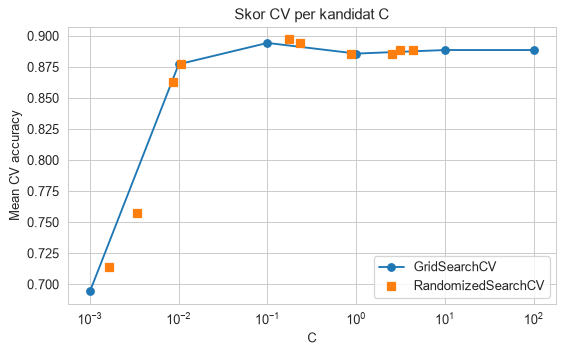

In [13]:
# Tambahan: skor CV tiap kandidat C dari kedua metode pencarian
g = pd.DataFrame(grid.cv_results_)[['param_C', 'mean_test_score', 'std_test_score']]
r = pd.DataFrame(random_search.cv_results_)[['param_C', 'mean_test_score', 'std_test_score']]
print('GridSearchCV:'); display(g.round(4))
print('RandomizedSearchCV (diurutkan menurut C):')
display(r.assign(param_C=r['param_C'].astype(float)).sort_values('param_C').round(4))

print(f'Best CV score  - grid: {grid.best_score_:.4f} | random: {random_search.best_score_:.4f}')
print(f'Akurasi uji model grid  : {grid.score(X_test, y_test):.3f}')
print(f'Akurasi uji model random: {random_search.score(X_test, y_test):.3f}')

plt.figure(figsize=(7, 4))
plt.semilogx(g['param_C'].astype(float), g['mean_test_score'], 'o-', label='GridSearchCV')
plt.semilogx(r['param_C'].astype(float), r['mean_test_score'], 's', label='RandomizedSearchCV')
plt.xlabel('C'); plt.ylabel('Mean CV accuracy'); plt.title('Skor CV per kandidat C')
plt.legend(); plt.show()

**Interpretasi:**

- Kurva skor CV vs C berbentuk "naik lalu datar": C sangat kecil (0.001–0.003) menghasilkan akurasi **0.69–0.76** — mendekati baseline mayoritas karena koefisien disusutkan hampir nol (*underfitting*). Mulai C ≈ 0.01 akurasi melonjak ke ~0.88, lalu stabil di **0.885–0.897** untuk C ≥ 0.1.
- Skor CV terbaik: grid **0.8943** (C = 0.1) vs random **0.8971** (C ≈ 0.174). Randomized search menemukan nilai sedikit lebih baik dengan 10 evaluasi (vs 6 pada grid), meskipun selisih 0.003 jauh lebih kecil dari simpangan baku antar fold (~0.015–0.02) — keduanya pada dasarnya setara.
- Akurasi uji: model grid **0.933**, model random **0.940** (selisih satu sampel dari 150). Pelajaran praktisnya: pada wilayah datar seperti ini pilihan tepat C tidak terlalu penting; yang penting adalah menghindari C yang terlalu kecil. Distribusi log-uniform terlihat dari sampel random yang tersebar merata per dekade (0.0017 hingga 4.33).

## 12.5 Mengevaluasi Generalisasi Model (Learning Curve dan Validation Curve)

**Teori:**

**Dekomposisi bias–varians.** Untuk loss kuadrat, galat harapan pada titik $x$ dapat diurai menjadi

$$
\mathbb{E}\big[(y-\hat f(x))^2\big] = \underbrace{\big(f(x)-\mathbb{E}\hat f(x)\big)^2}_{\text{bias}^2} + \underbrace{\operatorname{Var}\big(\hat f(x)\big)}_{\text{varians}} + \underbrace{\sigma^2}_{\text{noise}}.
$$

Model terlalu sederhana → bias tinggi (*underfitting*); model terlalu fleksibel → varians tinggi (*overfitting*). Dua diagnosis grafis membantu menentukan posisi model kita:

**Learning curve** (`learning_curve`): skor latih dan skor CV sebagai fungsi **ukuran data latih** $m$. Untuk setiap $m$ pada `train_sizes` (pecahan dari data latih tiap fold), model dilatih pada $m$ sampel pertama dari data latih fold lalu diuji pada fold validasi.
- Skor latih turun dan skor CV naik seiring $m$ bertambah; keduanya mendekati suatu asimtot.
- **Celah besar** antara keduanya → varians tinggi; menambah data kemungkinan membantu.
- **Keduanya rendah dan sudah konvergen** → bias tinggi; menambah data tidak membantu, perlu model/fitur yang lebih kaya.
- Catatan: argumen `random_state` pada `learning_curve` hanya berpengaruh bila `shuffle=True`; pada kode buku (tanpa shuffle) argumen ini tidak berefek.

**Validation curve** (`validation_curve`): skor latih dan skor CV sebagai fungsi **satu hyperparameter** kompleksitas (di sini $C$ regresi logistik).
- Wilayah kompleksitas rendah (C kecil): skor latih dan CV sama-sama rendah → underfitting.
- Wilayah kompleksitas tinggi: skor latih terus naik sementara skor CV turun → overfitting.
- Titik optimum = puncak kurva skor CV.

Ukuran data latih per fold untuk 1000 sampel dan 5-fold adalah 800; `train_sizes = linspace(0.1, 1.0, 5)` menghasilkan $m = 80, 260, 440, 620, 800$.

In [14]:
# Dataset lebih besar: 1000 sampel, 20 fitur, kelas tidak seimbang 70:30
X, y = make_classification(n_samples=1000, n_features=20, weights=[0.7, 0.3], random_state=2024)
print('Ukuran X:', X.shape, '| distribusi kelas:', np.bincount(y))

Ukuran X: (1000, 20) | distribusi kelas: [695 305]


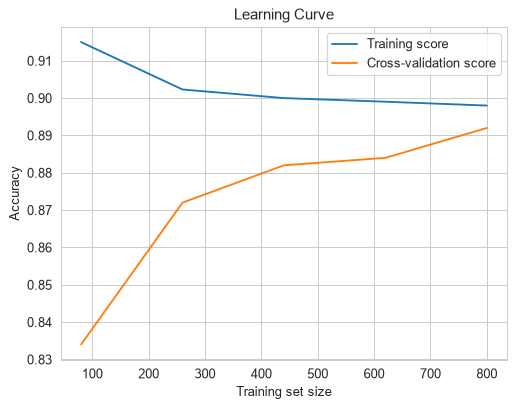

,train_size,train_acc,cv_acc,gap
0,80,0.9150,0.834,0.0810
1,260,0.9023,0.872,0.0303
2,440,0.9000,0.882,0.0180
3,620,0.8990,0.884,0.0150
4,800,0.8980,0.892,0.0060


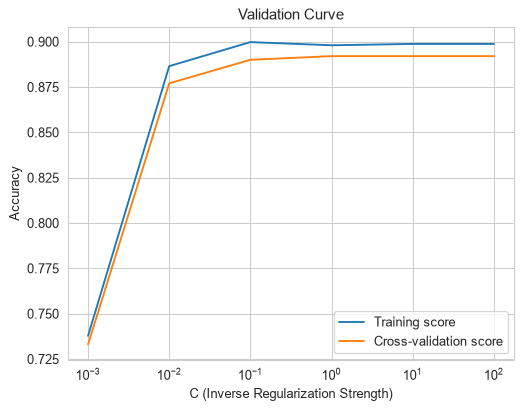

,C,train_acc,cv_acc,cv_std
0,0.001,0.7377,0.733,0.0150
1,0.010,0.8865,0.877,0.0232
2,0.100,0.8998,0.890,0.0212
3,1.000,0.8980,0.892,0.0242
4,10.000,0.8988,0.892,0.0242
5,100.000,0.8988,0.892,0.0242


In [15]:
# Learning curve: skor latih vs skor CV untuk berbagai ukuran data latih
train_sizes, train_scores, test_scores = learning_curve(
    LogisticRegression(), X, y, cv=5, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 5), random_state=2024)

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.plot(train_sizes, train_mean, label='Training score')
plt.plot(train_sizes, test_mean, label='Cross-validation score')
plt.xlabel('Training set size')
plt.ylabel('Accuracy')
plt.title('Learning Curve')
plt.legend()
plt.grid(True)
plt.show()
display(pd.DataFrame({'train_size': train_sizes, 'train_acc': train_mean,
                      'cv_acc': test_mean, 'gap': train_mean - test_mean}).round(4))

# Validation curve: skor latih vs skor CV untuk berbagai nilai C
param_range = np.logspace(-3, 2, 6)
train_scores, test_scores = validation_curve(
    LogisticRegression(), X, y, param_name="C", param_range=param_range,
    cv=5, scoring='accuracy')

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.semilogx(param_range, train_mean, label='Training score')
plt.semilogx(param_range, test_mean, label='Cross-validation score')
plt.xlabel('C (Inverse Regularization Strength)')
plt.ylabel('Accuracy')
plt.title('Validation Curve')
plt.legend()
plt.grid(True)
plt.show()
display(pd.DataFrame({'C': param_range, 'train_acc': train_mean,
                      'cv_acc': test_mean, 'cv_std': test_scores.std(axis=1)}).round(4))

**Interpretasi:**

*Learning curve:*
- Pada $m=80$, akurasi latih **0.915** dan CV **0.834** — celah **0.081** menandakan varians tinggi ketika data sangat sedikit (20 koefisien diestimasi dari 80 sampel).
- Seiring $m$ bertambah, skor latih turun perlahan ke **0.898** dan skor CV naik ke **0.892**; celah menyempit menjadi hanya **0.006** pada $m=800$. Kedua kurva hampir bertemu, artinya model sudah memanfaatkan data dengan baik dan **tidak overfitting**.
- Karena kedua kurva sudah konvergen di sekitar 0.89–0.90, menambah data kemungkinan tidak akan banyak menaikkan akurasi. Batas ini adalah bias model linear (dan *noise* label bawaan `make_classification`); untuk peningkatan lebih lanjut dibutuhkan model yang lebih fleksibel atau fitur baru.

*Validation curve:*
- **C = 0.001** (regularisasi sangat kuat): akurasi latih **0.738** dan CV **0.733** — keduanya rendah dan hampir sama, ciri khas *underfitting* (hanya sedikit di atas baseline mayoritas 0.695).
- Mulai **C = 0.1** kurva mendatar: akurasi latih ≈ **0.90** dan CV ≈ **0.89**, dengan celah hanya ~0.01. Untuk C = 1 sampai 100 skor identik (0.892) karena penalti L2 sudah sangat lemah dan solusi praktis sama dengan regresi logistik tanpa regularisasi.
- Tidak terlihat wilayah overfitting: dengan 1000 sampel dan hanya 20 fitur, regresi logistik linear tidak cukup fleksibel untuk overfitting meskipun regularisasi dihilangkan. Pilihan aman adalah C di rentang 0.1–1.

## Latihan

Bagian ini mereproduksi tiga latihan di akhir chapter beserta solusinya (dari notebook *Exercise Solutions*). Ketiganya memakai dataset `make_classification(n_samples=500, n_features=10, random_state=2024)` yang **seimbang** (default `weights=None`).

**Teori singkat:** latihan-latihan ini merangkum alur kerja evaluasi model: (1) mengevaluasi satu model dengan beberapa metrik lewat `cross_validate`, (2) memilih kombinasi hyperparameter dengan `GridSearchCV` lalu menguji pada *test set* terpisah, dan (3) mendiagnosis generalisasi lewat learning/validation curve. Pada Exercise 2 dipakai **Support Vector Classifier** (SVC): mencari *hyperplane* dengan margin maksimum, $\min \tfrac12\lVert\mathbf w\rVert^2 + C\sum_i\xi_i$, dengan kernel `linear` ($K(x,x')=x^\top x'$) atau `rbf` ($K(x,x')=\exp(-\gamma\lVert x-x'\rVert^2)$). $C$ besar = margin sempit dan sedikit pelanggaran yang ditoleransi (model lebih kompleks).

### Exercise 1: Cross-Validating a Logistic Regression Model

In [16]:
# Exercise 1: cross_validate dengan beberapa metrik
X, y = make_classification(n_samples=500, n_features=10, random_state=2024)

model = LogisticRegression()
results = cross_validate(model, X, y, cv=5, scoring=["accuracy", "precision", "recall", "f1"])

for metric in ["test_accuracy", "test_precision", "test_recall", "test_f1"]:
    print(f"{metric}: {results[metric].mean():.3f}")

test_accuracy: 0.896
test_precision: 0.896
test_recall: 0.895
test_f1: 0.895


**Interpretasi:**

Akurasi, precision, recall dan F1 semuanya ≈ **0.895–0.896**. Pada data seimbang keempat metrik cenderung berdekatan karena kesalahan pada kedua kelas kurang lebih sama banyak (FP ≈ FN). Bandingkan dengan resep 12.3 (data 70:30) di mana recall (0.82) jelas lebih rendah dari akurasi (0.91) — di situlah pentingnya melaporkan banyak metrik.

### Exercise 2: Tuning Hyperparameters with Grid Search

In [17]:
# Exercise 2: GridSearchCV untuk SVC (C x kernel = 6 kombinasi)
X, y = make_classification(n_samples=500, n_features=10, random_state=2024)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

param_grid = {"C": [0.1, 1, 10], "kernel": ["linear", "rbf"]}
grid = GridSearchCV(SVC(), param_grid, cv=5)
grid.fit(X_train, y_train)
print(f"Best parameters: {grid.best_params_}")
print(f"Best CV accuracy: {grid.best_score_:.3f}")

# Evaluasi pada data uji
y_pred = grid.predict(X_test)
print(classification_report(y_test, y_pred))

display(pd.DataFrame(grid.cv_results_)[['param_C', 'param_kernel', 'mean_test_score', 'rank_test_score']]
        .sort_values('rank_test_score').round(4))

Best parameters: {'C': 0.1, 'kernel': 'rbf'}
Best CV accuracy: 0.897
              precision    recall  f1-score   support

           0       0.94      0.86      0.89        84
           1       0.84      0.92      0.88        66

    accuracy                           0.89       150
   macro avg       0.89      0.89      0.89       150
weighted avg       0.89      0.89      0.89       150



,param_C,param_kernel,mean_test_score,rank_test_score
1,0.1,rbf,0.8971,1
3,1.0,rbf,0.8971,1
4,10.0,linear,0.8971,1
0,0.1,linear,0.8914,4
2,1.0,linear,0.8914,4
5,10.0,rbf,0.8543,6


**Interpretasi:**

- Tiga kombinasi **seri** di peringkat 1 dengan akurasi CV **0.897**: (C=0.1, rbf), (C=1, rbf) dan (C=10, linear). Bila terjadi seri, `GridSearchCV` memilih kandidat pertama sesuai urutan grid, yaitu **{'C': 0.1, 'kernel': 'rbf'}**. Kombinasi terburuk adalah (C=10, rbf) dengan **0.854** — kernel RBF dengan C besar mulai overfitting.
- Pada *test set* (150 sampel) akurasi **0.89**. Kelas 0 memiliki precision tinggi (0.94) tetapi recall 0.86, sedangkan kelas 1 sebaliknya (precision 0.84, recall 0.92): model sedikit cenderung memprediksi kelas 1. Macro-F1 0.89 konsisten dengan skor CV (0.897), menandakan estimasi CV dapat dipercaya.
- Karena kernel linear dan RBF memberi skor hampir sama, model linear yang lebih sederhana pun sudah memadai untuk data ini.

### Exercise 3: Assessing Model Generalization with Learning and Validation Curves

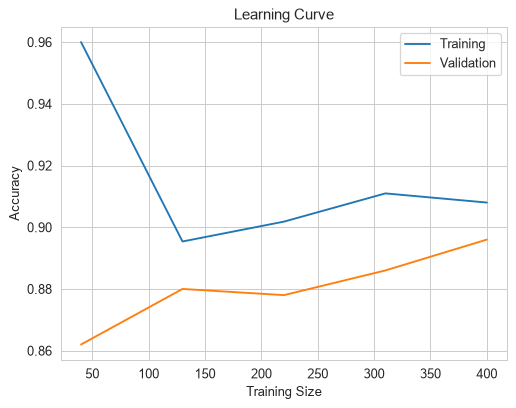

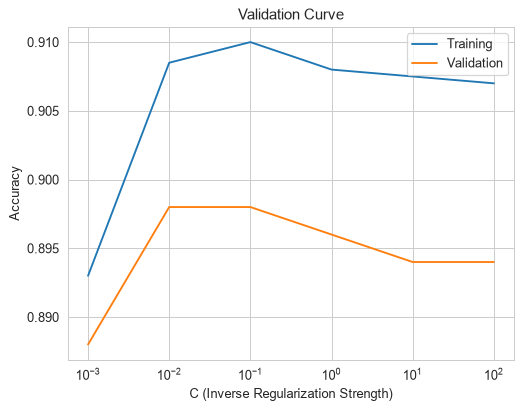

,train_size,train_acc,val_acc
0,40,0.9600,0.862
1,130,0.8954,0.880
2,220,0.9018,0.878
3,310,0.9110,0.886
4,400,0.9080,0.896


,C,train_acc,val_acc
0,0.001,0.8930,0.888
1,0.010,0.9085,0.898
2,0.100,0.9100,0.898
3,1.000,0.9080,0.896
4,10.000,0.9075,0.894
5,100.000,0.9070,0.894


In [18]:
# Exercise 3: learning curve dan validation curve (memakai X, y dari Exercise 2)
train_sizes, train_scores, test_scores = learning_curve(
    LogisticRegression(), X, y, cv=5, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 5), random_state=2024)

plt.plot(train_sizes, train_scores.mean(axis=1), label="Training")
plt.plot(train_sizes, test_scores.mean(axis=1), label="Validation")
plt.title("Learning Curve")
plt.xlabel("Training Size")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()
lc = pd.DataFrame({'train_size': train_sizes, 'train_acc': train_scores.mean(axis=1),
                   'val_acc': test_scores.mean(axis=1)}).round(4)

param_range = np.logspace(-3, 2, 6)
train_scores, test_scores = validation_curve(
    LogisticRegression(), X, y, param_name="C", param_range=param_range,
    cv=5, scoring='accuracy')

plt.semilogx(param_range, train_scores.mean(axis=1), label="Training")
plt.semilogx(param_range, test_scores.mean(axis=1), label="Validation")
plt.title("Validation Curve")
plt.xlabel("C (Inverse Regularization Strength)")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()
vc = pd.DataFrame({'C': param_range, 'train_acc': train_scores.mean(axis=1),
                   'val_acc': test_scores.mean(axis=1)}).round(4)
display(lc); display(vc)

**Interpretasi:**

- Dataset seluruhnya 500 sampel, jadi data latih per fold 400 dan `train_sizes` = 40, 130, 220, 310, 400.
- *Learning curve:* pada 40 sampel akurasi latih **0.960** vs validasi **0.862** (celah ~0.10, varians tinggi). Dari 130 sampel ke atas akurasi latih stabil ~**0.90–0.91** dan validasi naik ke **0.896** pada 400 sampel; celah tersisa ~0.01, jadi model sudah mendekati batas kemampuannya.
- *Validation curve:* berbeda dari 12.5, bahkan **C = 0.001** sudah menghasilkan akurasi validasi **0.888** — data seimbang dengan fitur yang informatif tetap dapat dipisahkan meski koefisien disusutkan kuat (pada data seimbang, menyusutkan koefisien tidak menggeser prediksi ke satu kelas mayoritas). Puncak akurasi validasi **0.898** pada C = 0.01–0.1, lalu turun sedikit ke 0.894 untuk C ≥ 10. Penurunan kecil ini adalah sinyal overfitting yang sangat ringan; kurva latih dan validasi tetap berdekatan (selisih ≤ 0.013) di semua nilai C.

## Ringkasan Chapter 12

1. **Galat latih bukan ukuran generalisasi.** Validasi silang K-Fold melatih model $K$ kali pada $K-1$ fold dan mengujinya pada fold sisanya, sehingga setiap observasi dipakai sekali sebagai data uji. Rata-rata skor memberi estimasi performa, dan simpangan baku antar fold memberi ukuran ketidakpastiannya.
2. **Stratified K-Fold** menjaga proporsi kelas di setiap fold. Pada data chapter ini rata-rata akurasinya mirip K-Fold biasa (0.766 vs 0.756), tetapi simpangan baku antar fold turun drastis (0.013 vs 0.071). Fungsi tingkat tinggi scikit-learn otomatis memakai stratifikasi untuk classifier.
3. **LOOCV** ($K=n$) memiliki bias sangat kecil tetapi mahal dan bervarians tinggi. Pada dataset diabetes MSE LOOCV (3328) hanya sedikit lebih rendah dari 5-fold (3411) dan 10-fold (3351), sehingga 5–10 fold biasanya sudah cukup.
4. **Nested CV** memisahkan tuning (loop dalam) dari evaluasi (loop luar) untuk menghindari bias optimistis `best_score_`. Ridge pada data diabetes memperoleh $R^2$ nested ≈ 0.48–0.49, dan $\alpha$ terbaik berbeda antar fold (0.01 atau 0.1).
5. **API scikit-learn:** `cross_val_score` (satu metrik), `cross_validate` (banyak metrik + waktu), `GridSearchCV` (tuning + refit). Pada data tidak seimbang 70:30, akurasi 0.91 perlu dibaca bersama precision 0.875, recall 0.82 dan baseline mayoritas 0.70.
6. **Pemilihan model:** Grid search menguji semua kombinasi, sedangkan randomized search mengambil sampel dari distribusi (misalnya `loguniform`) dengan anggaran `n_iter`. Randomized search menemukan C ≈ 0.174 (CV 0.897, uji 0.940), sebanding dengan grid C = 0.1 (CV 0.894, uji 0.933). Test set dipisahkan sebelum tuning dan hanya dipakai sekali.
7. **Learning curve dan validation curve** mendiagnosis bias–varians. Pada data 1000 sampel celah latih–CV menyempit dari 0.081 menjadi 0.006, sehingga model tidak overfitting dan menambah data tidak akan banyak membantu. C terlalu kecil (0.001) menyebabkan underfitting (akurasi 0.73), sedangkan C ≥ 0.1 sudah optimal.
8. **Latihan** menegaskan alur lengkap: evaluasi multi-metrik (≈0.895 pada data seimbang), tuning SVC (3 kombinasi seri di 0.897 dan akurasi uji 0.89), serta diagnosis kurva yang menunjukkan model linear sudah mendekati batasnya.

**Pesan utama:** selalu evaluasi model dengan validasi silang (stratified untuk klasifikasi), laporkan rata-rata *dan* variasi skor, gunakan beberapa metrik yang relevan, lakukan tuning hanya pada data latih (atau dengan nested CV), dan gunakan learning/validation curve untuk memutuskan apakah perlu menambah data, mengubah regularisasi, atau mengganti model.